### This file is to be ran after cleaning and pre-processing steps. The input file is the cleaned csv file.

# Load Libraries

In [57]:
import pandas as pd                                   
import numpy as np                                    
from scipy.cluster.hierarchy import linkage, fcluster 
from scipy.spatial.distance import squareform         
import seaborn as sns                                 
import matplotlib.pyplot as plt     

# Load Data

In [58]:
# load cleaned up data table
clean_data = pd.read_csv("clean_table.csv", parse_dates=["timestamp"])

X = clean_data.drop(columns=["Unit_ID", "label", "timestamp"]) #drop non sensor cols

sensors_kept = list(X.columns) # list of sensor names that are kept after cleaning the data

print("table shape:", clean_data.shape)
print("sensors:", len(keep))

table shape: (1567, 449)
sensors: 446


# Compute rank correlation between all pairs of sensors

In [59]:
# We are handling blank cells by filling it in with the sensors median reading
X_filled = X[keep].fillna(X[keep].median())


# rank correlation: 0 = unrelated, 1 = perfect correlation
# take abs value so positive and negative correlation count the same
R = X_filled.corr(method="spearman").abs()


# To avoid double counting -  keep each pair only once (upper triangle, no diagonal) 
hide = np.triu(np.ones(R.shape), k=1).astype(bool)
upper = R.where(hide).stack()


print("pairs above 0.9:", (upper > 0.9).sum())
print("pairs above 0.95:", (upper > 0.95).sum())
print("pairs above 0.99:", (upper > 0.99).sum()) 

pairs above 0.9: 296
pairs above 0.95: 223
pairs above 0.99: 91


# Hierarchial Clustering -> Group Sensors into teams and families

In [60]:
# Turn correlation into distance: highly correlated near 0, unrelated sensors near 1
D = 1 - R


## hierarchial clustering bottom up
Z = linkage(squareform(D.values, checks=False), method="complete")    # Repeatedly merge the two closest sensors/groups until all are joined then Z stores the record of every merge

# preview -- output:[Group A, Group B, Distance when merged, Size of new group]
print(Z[:5], end="\n\n")


# making two cuts here .95 is what we are declaring we are merging near duplicate sensors into teams, and .8 is what we are calling "families"
team = pd.Series(fcluster(Z, t=0.05, criterion="distance"), index=keep)
family = pd.Series(fcluster(Z, t=0.20, criterion="distance"), index=keep)


# Split up single sensor from multi sensor teams just to see
sizes = team.value_counts()
multi = sizes[sizes >= 2]
single = sizes[sizes == 1]


print("total teams:", len(sizes))  # expect 295
print("multi-sensor teams:", len(multi), "-> # of sensors in them:", multi.sum())
print("single-sensor teams:", len(single),end="\n\n") 
print(sizes.value_counts().sort_index())

[[ 66. 180.   0.   2.]
 [183. 446.   0.   3.]
 [273. 447.   0.   4.]
 [276. 448.   0.   5.]
 [368. 449.   0.   6.]]

total teams: 295
multi-sensor teams: 100 -> # of sensors in them: 251
single-sensor teams: 195

count
1    195
2     57
3     39
4      2
6      2
Name: count, dtype: int64


# Assign "team leader" -> the sensor that best represents the readings of the whole team

In [61]:
# Share of blanks per sensor - calculted to decentivize picking a sensor with lots of blanks 
missing = X[sensors_kept].isna().mean()

team_leaders = [] 


# pick the sensor from each group that is most correlated with other sensors in its team and save it - if just one sensor in team it is chosen by defautl
for t in team.unique():                               
    members = list(team[team == t].index)             

    closeness = R.loc[members, members].mean()

    # Sort members - highest closeness first, then fewest blanks; take the first one
    best = sorted(members, key=lambda s: (-closeness[s], missing[s]))[0]

    team_leaders.append(best)                                 


# quick check - should match num of teams from previous cell (295)
print("Chosen Team Leaders:", len(team_leaders)) 

Chosen Team Leaders: 295


# Variance Inflation Factor (VIF)

In [62]:
# VIF of 1 = no overlap; above 10 = heavy overlap

Xr = X_filled[team_leaders]  # table of team leaders

## Note i had to change method because the statsmodel function was too slow
#VIFs are the diagonal of the inverse of the correlation matrix -- calcs much faster
corr_matrix = Xr.corr().values 
vif_values = np.diag(np.linalg.inv(corr_matrix))

# Put the numbers next to sensor names and sort biggest first
vif = pd.Series(vif_values, index=team_leaders).sort_values(ascending=False)

print("VIF above 10:", (vif > 10).sum()) # these are the ones we want to flag
print(vif.head(10).round(1)) #top 10 VIF -- can change to whatever



## note 133 of our 295 have VIF above 10
# so we still have lots correlation between the groups even though we've sorted out the single sensor "duplicates"

VIF above 10: 133
Sensor_051    93701.5
Sensor_046    75988.0
Sensor_044    48243.2
Sensor_005    33103.1
Sensor_141    32910.8
Sensor_049    25466.8
Sensor_071    16101.9
Sensor_252    15535.0
Sensor_390    15445.4
Sensor_063    13178.1
dtype: float64


# Heatmap visual - complete list

C:\Users\mewol\anaconda3\envs\IE590\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
C:\Users\mewol\anaconda3\envs\IE590\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


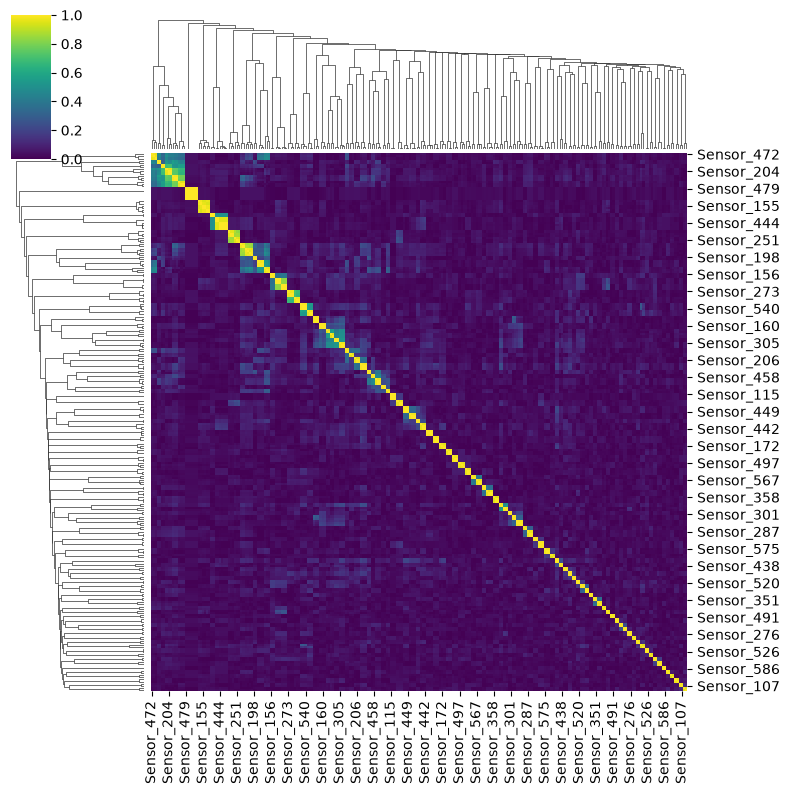

In [63]:
# keep only teams with 2+ sensors
sizes = team.value_counts()
multi_teams = sizes[sizes >= 2].index

# Sensor names that belong to each team
show = list(team[team.isin(multi_teams)].index)


sns.clustermap(R.loc[show, show], cmap="viridis", figsize=(8, 8))

plt.show()

# Heatmap - 60 largest teams

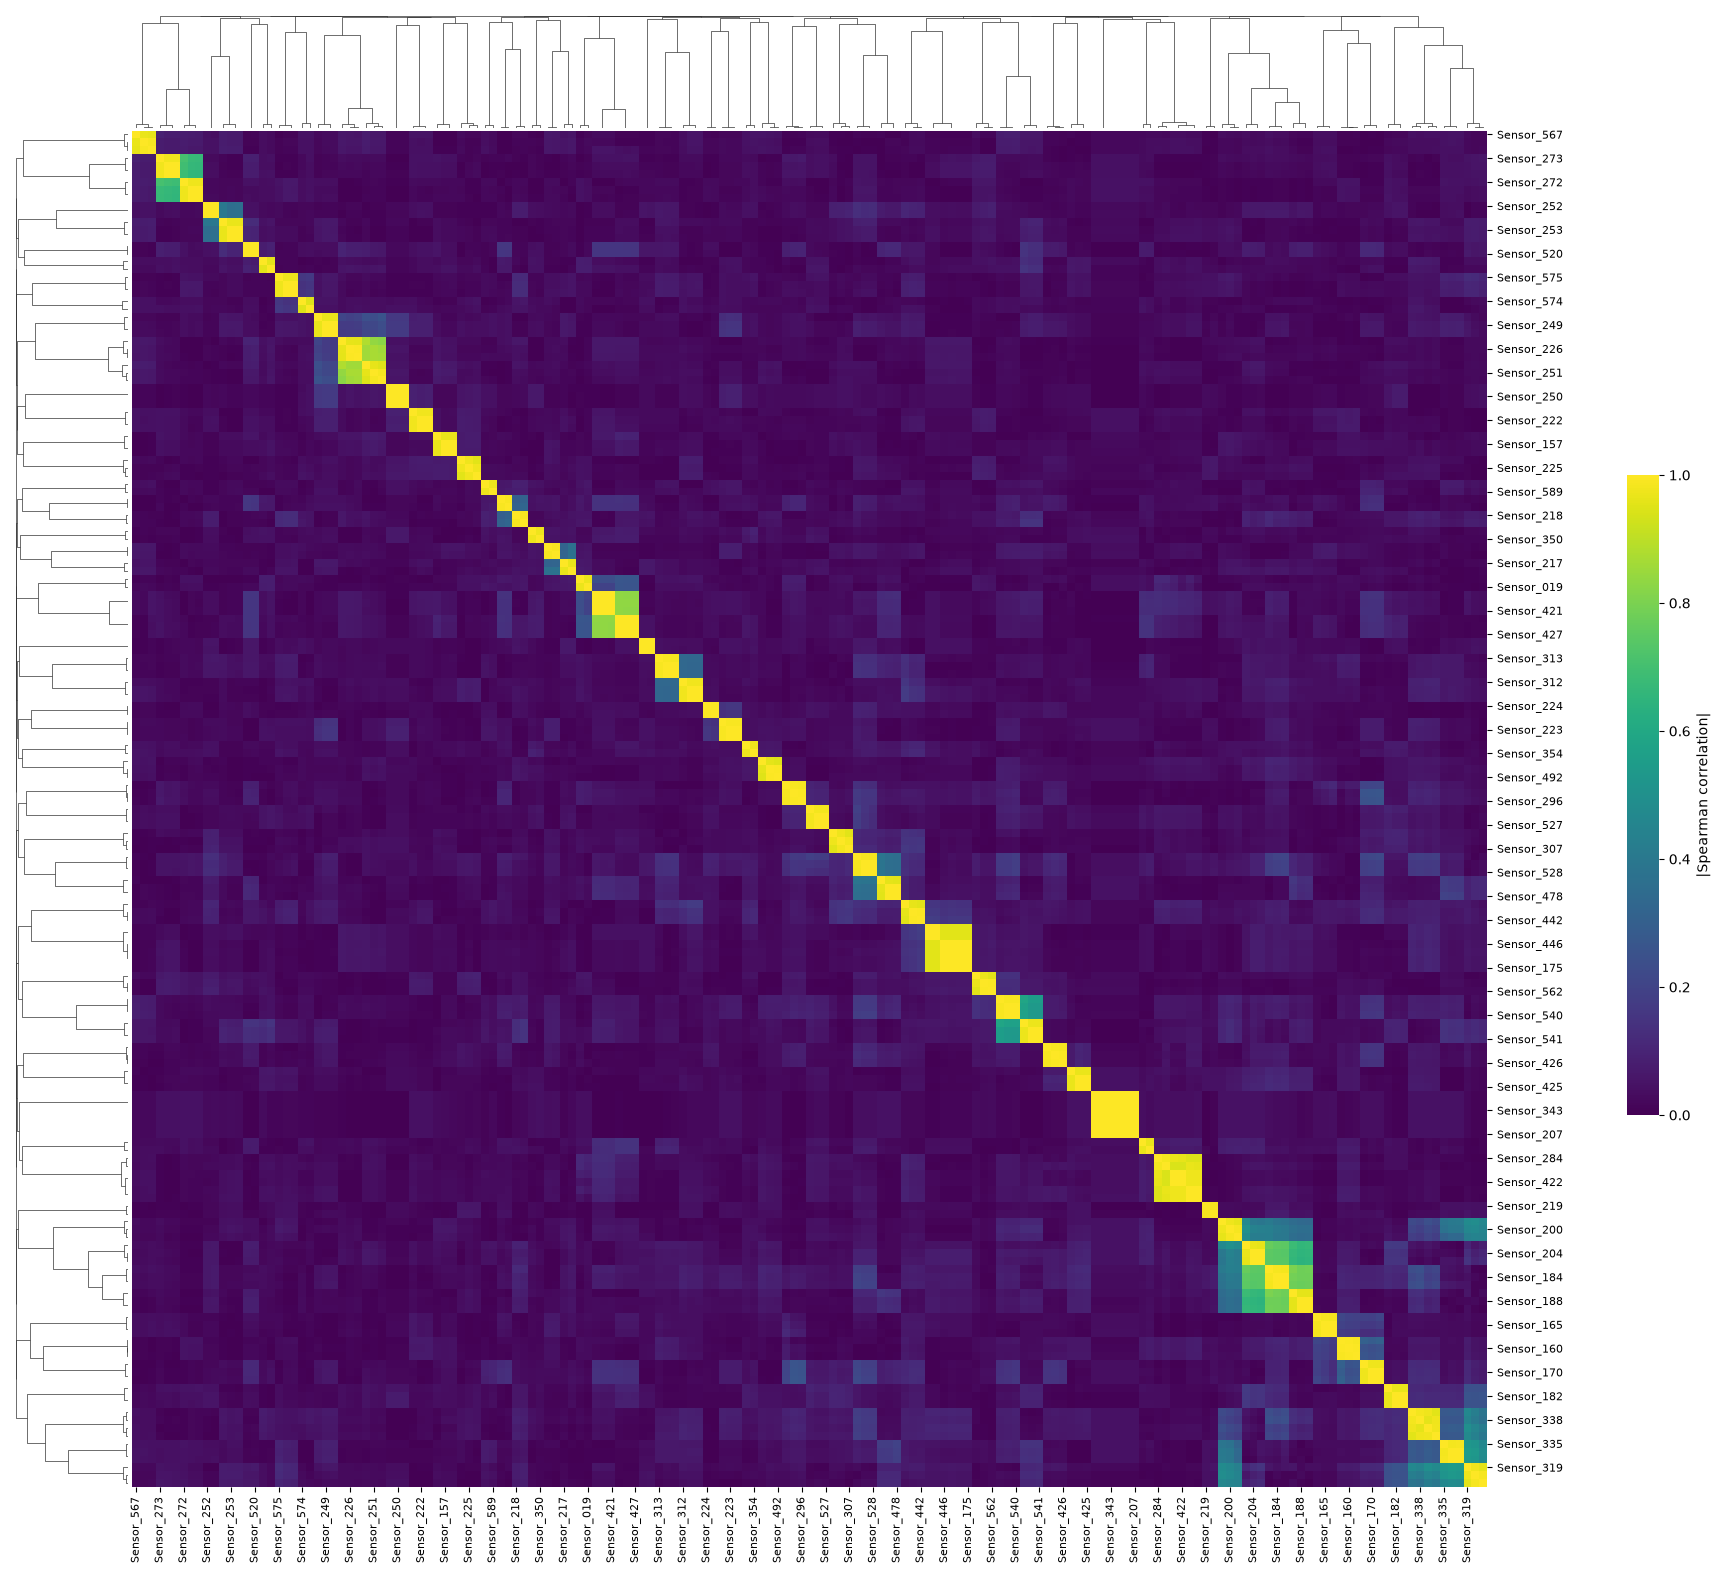

In [64]:
# this would prob be more helpful in real life application

top_teams = team.value_counts().head(60).index # team numbers of the X biggest teams
show = list(team[team.isin(top_teams)].index)
R_show = R.loc[show, show]

# Order the sensors with the same method as earlier
Z_show = linkage(squareform((1 - R_show).values, checks=False), method="complete")

g = sns.clustermap(
    R_show,
    row_linkage=Z_show, col_linkage=Z_show,
    cmap="viridis", vmin=0, vmax=1,
    xticklabels="auto", yticklabels="auto", 
    figsize=(16, 16),
    dendrogram_ratio=0.08,
    cbar_pos=(1.02, 0.3, 0.02, 0.4),
)

g.ax_heatmap.tick_params(labelsize=8) 
g.cax.set_ylabel("|Spearman correlation|") 

plt.show()

# Bootstrap Check -> use 50 re-samples to make sure strong teams stay together

In [65]:
# All pairs with correlation above 0.95 - twins we decided earlier
## kind of a long step - takes maybe a minute
strong_pairs = list(upper[upper > 0.95].index)

# Counter for num of strong pairs staying together
together = pd.Series(0, index=pd.MultiIndex.from_tuples(strong_pairs))

# used 50 resamples
for b in range(50):                                  
    sample = X_filled.sample(frac=1, replace=True, random_state=b)

    # Redo rank and hierarchial clustering on the resamples
    Rb = sample.corr(method="spearman").abs().fillna(0)
    Zb = linkage(squareform((1 - Rb).values, checks=False), method="complete")
    team_b = pd.Series(fcluster(Zb, t=0.05, criterion="distance"), index=sensors_kept)

    # For each strong pair, add 1 if both sensors are on team together again
    for a, c in strong_pairs:
        if team_b[a] == team_b[c]:
            together[(a, c)] += 1

# proportion that studk together
still_together = together / 50

print("strong pairs:", len(strong_pairs))
print("proprtion kept together >90% of the time:", round((still_together > 0.9).mean(), 3))

# Which pairs got split up often - maybe worth looing into
print(still_together.sort_values().head(15))


## we missed target of 90% --> 82.%% was result (for 50 resamples)

strong pairs: 223
proprtion kept together >90% of the time: 0.825
Sensor_149  Sensor_284    0.00
Sensor_155  Sensor_290    0.00
Sensor_284  Sensor_422    0.00
Sensor_290  Sensor_428    0.00
Sensor_552  Sensor_555    0.20
Sensor_186  Sensor_322    0.26
Sensor_145  Sensor_280    0.38
Sensor_251  Sensor_389    0.66
Sensor_389  Sensor_523    0.66
Sensor_207  Sensor_348    0.72
            Sensor_343    0.72
            Sensor_210    0.72
Sensor_075  Sensor_479    0.72
            Sensor_343    0.72
            Sensor_348    0.72
dtype: float64
